### Procesamiento de Lenguaje Natural I
# Desafío 3
### Alumno: Nicolás Moguilner Reh (a2623)

## Consigna del Desafío 3
- Seleccionar un corpus de texto sobre el cual entrenar el modelo de lenguaje.
- Realizar el pre-procesamiento adecuado para tokenizar el corpus, estructurar el dataset y separar entre datos de entrenamiento y validación.
- Proponer arquitecturas de redes neuronales basadas en unidades recurrentes para implementar un modelo de lenguaje.
- Con el o los modelos que consideren adecuados, generar nuevas secuencias a partir de secuencias de contexto con las estrategias de greedy search y beam search determístico y estocástico. En este último caso observar el efecto de la temperatura en la generación de secuencias.

Sugerencias:
- Durante el entrenamiento, guiarse por el descenso de la perplejidad en los datos de validación para finalizar el entrenamiento. Para ello se provee un callback.
- Explorar utilizar SimpleRNN (celda de Elman), LSTM y GRU.
- rmsprop es el optimizador recomendado para la buena convergencia. No obstante se pueden explorar otros.

---
## Modelo de lenguaje por caracteres con la obra de Borges

Se entrena un modelo de lenguaje que predice el próximo caracter a partir de los anteriores. Como corpus se usan las Obras Completas 1923-1972 de Jorge Luis Borges, que incluyen poesía, ensayos y cuentos (Fervor de Buenos Aires, Ficciones, El Aleph, El hacedor, El informe de Brodie, entre otros).

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # menos mensajes de TensorFlow en la salida

import re
import time
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bs4 as bs
from scipy.special import softmax

import tensorflow as tf
from tensorflow import keras
from keras import layers
from keras.models import Sequential

tf.get_logger().setLevel('ERROR')  # oculta avisos de retracing y de GPU no disponible en Windows
keras.utils.set_random_seed(42)

## Datos

El libro está en archive.org. El texto completo viene en un HTML dentro de un tag `<pre>`, así que se parsea con BeautifulSoup igual que en el ejemplo de Julio Verne. Se guarda una copia local para no descargarlo cada vez.

In [2]:
URL = ('https://archive.org/stream/jorge-luis-borges-obras-completas-1923-1972-1984/'
       'Jorge%20Luis%20Borges%20-%20Obras%20Completas%201923-1972%20%281984%29_djvu.txt')
DATA_DIR = 'data'
HTML = os.path.join(DATA_DIR, 'borges_obras_completas.html')

if not os.path.exists(HTML):
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(URL, HTML)
else:
    print('El texto ya se encuentra descargado')

with open(HTML, 'rb') as f:
    article_html = bs.BeautifulSoup(f.read(), 'lxml')

raw_text = article_html.find('pre').text
print(f'Caracteres: {len(raw_text)}')

Caracteres: 2052778


In [3]:
print(raw_text[2400:3400])

es 


Quiero dejar escrita una confesión. que a un tiempo. será 
intima y general, ya que las cosas que le ocurren a tun 
hombre les ocurren a todos. Estoy hablando de algo ya 
remoto y perdido, los días. de mi santo, los más antiguos. 
Yo recibía los regalos y yo pensaba que no era más que 
tn chico y que no habia hecho nada, absolutamente nada, 
para merecerlos. Por supuesto, nunca lo dije; la niñiez es 
timida, Desde entonces me has dado tantas cosas y son 
tantos los años y los recuerdos. Padre, Norah, los abuelos, 
tu memoria y en ella la memoria de los mayores —tos 
patios, los esclavos, el aguaters. la carga de los husares 
del Perú y el oprobio de Rosas—, tu prisión valerosa, 
cuando tantos hombres callabamos, las mañanas del Paso 
del Molino, de Ginebra y de Austin, las compartidas cla 
ridades y sombras, tu fresca ancianidad, tu amor a Di 
ckens y a Eqa de Queiroz, Madre, vos misma. 

Aqui estamos hablando los dos, et tout le reste ost litié- 
rature, como escribió, con excel

## 1 - Preprocesamiento

El texto sale de un OCR del libro escaneado, así que tiene bastante ruido. Si no se limpia, el modelo aprende a generar números de página y encabezados. Se hace lo siguiente:
* Se saca la portada del principio y el índice del final.
* Se eliminan los encabezados de página (`418 JORGE LUIS BORGES—OBRAS COMPLETAS`, `FICCIONES 431`) y los números de página sueltos.
* Se unen las palabras cortadas con guion al final de la línea (`li- teratura` → `literatura`).
* Se pasa todo a minúscula, se unifican comillas y guiones y se sacan los caracteres raros del OCR (`|`, `_`, `€`, `$`).
* Los saltos de línea se reemplazan por espacios.

In [4]:
inicio = raw_text.find('Quiero dejar escrita')  # dedicatoria "A Leonor Acevedo de Borges"
fin = raw_text.find('\nIndice \n')            # índice final
texto = raw_text[inicio:fin]

def es_encabezado(linea):
    s = linea.strip()
    if 'OBRAS COMPLETAS' in s:
        return True
    letras = re.sub(r'[^A-Za-zÁÉÍÓÚÑÜáéíóúñü]', '', s)
    if re.search(r'\d', s) and letras and letras.upper() == letras:  # título del libro + número de página
        return True
    return not letras  # números de página sueltos

lineas = texto.split('\n')
encabezados = [l.strip() for l in lineas if l.strip() and es_encabezado(l)]
print(f'Líneas eliminadas: {len(encabezados)}. Ejemplos: {encabezados[:6]}')
texto = '\n'.join(l for l in lineas if not es_encabezado(l))

texto = re.sub(r'(\w)-\s*\n\s*(\w)', r'\1\2', texto)  # palabras cortadas al final de línea
texto = texto.lower()
for a, b in [('“', '"'), ('”', '"'), ('«', '"'), ('»', '"'), ('‘', "'"), ('’', "'"), ('—', '-'), ('–', '-'), ('…', '...')]:
    texto = texto.replace(a, b)

permitidos = set('abcdefghijklmnopqrstuvwxyzáéíóúüñ0123456789 .,;:¿?¡!"\'()-\n')
descartados = Counter(ch for ch in texto if ch not in permitidos)
print(f'Caracteres descartados: {sum(descartados.values())}. Más frecuentes: {descartados.most_common(8)}')

texto = ''.join(ch for ch in texto if ch in permitidos)
article_text = re.sub(r'\s+', ' ', texto).strip()
print(f'Caracteres del corpus limpio: {len(article_text)}')

Líneas eliminadas: 1236. Ejemplos: ['(1923)', 'FERVOR DE BUENOS AIRES 7', 'JORGE LUIS BORGES—OBRAS COMPLETAS', 'FERYOR DE BUENOS AIRES 19', 'FORGE LUIS BORGES—OBRAS COMPLETAS', 'JORGE LUIS RORGES—OBRAS COMPLETAS']


Caracteres descartados: 1552. Más frecuentes: [('_', 407), ('|', 309), ('€', 192), ('$', 147), ('*', 141), (']', 60), ('>', 57), ('=', 51)]


Caracteres del corpus limpio: 1927014


In [5]:
# en article_text se encuentra el texto de toda la obra
article_text[:1000]

"quiero dejar escrita una confesión. que a un tiempo. será intima y general, ya que las cosas que le ocurren a tun hombre les ocurren a todos. estoy hablando de algo ya remoto y perdido, los días. de mi santo, los más antiguos. yo recibía los regalos y yo pensaba que no era más que tn chico y que no habia hecho nada, absolutamente nada, para merecerlos. por supuesto, nunca lo dije; la niñiez es timida, desde entonces me has dado tantas cosas y son tantos los años y los recuerdos. padre, norah, los abuelos, tu memoria y en ella la memoria de los mayores -tos patios, los esclavos, el aguaters. la carga de los husares del perú y el oprobio de rosas-, tu prisión valerosa, cuando tantos hombres callabamos, las mañanas del paso del molino, de ginebra y de austin, las compartidas cla ridades y sombras, tu fresca ancianidad, tu amor a di ckens y a eqa de queiroz, madre, vos misma. aqui estamos hablando los dos, et tout le reste ost litiérature, como escribió, con excelente literatura, 'ertame.

Interpretación: el texto original tiene unos 2,05 millones de caracteres y después de limpiarlo quedan 1,93 millones. Se eliminan 1236 líneas de encabezados y números de página, algunas con errores del OCR (`FORGE LUIS`, `RORGES`). Los caracteres descartados son pocos (1552), casi todos `_`, `|` y `€`.

Quedan errores dentro de las palabras que no se pueden arreglar con reglas simples, por ejemplo en el primer párrafo aparecen "tun hombre", "tn chico" y "cla ridades". Son pocos, pero el modelo también los aprende.

## 2 - Tokenizar

Como el modelo es por caracteres, el vocabulario es el conjunto de caracteres distintos del texto. Los índices arrancan en 1 y el 0 queda reservado para el padding, así no se confunde con un caracter real.

In [6]:
chars_vocab = sorted(set(article_text))
char2idx = {ch: i + 1 for i, ch in enumerate(chars_vocab)}  # el 0 queda reservado
idx2char = {i: ch for ch, i in char2idx.items()}
vocab_size = len(chars_vocab) + 1

print(f'Caracteres distintos: {len(chars_vocab)}')
print(''.join(chars_vocab))

Caracteres distintos: 56
 !"'(),-.0123456789:;?abcdefghijklmnopqrstuvwxyz¡¿áéíñóú


In [7]:
tokenized_text = np.array([char2idx[ch] for ch in article_text], dtype=np.int32)
tokenized_text[:50]

array([39, 43, 31, 27, 40, 37,  1, 26, 27, 32, 23, 40,  1, 27, 41, 25, 40,
       31, 42, 23,  1, 43, 36, 23,  1, 25, 37, 36, 28, 27, 41, 31, 55, 36,
        9,  1, 39, 43, 27,  1, 23,  1, 43, 36,  1, 42, 31, 27, 35, 38],
      dtype=int32)

## 3 - Estructurar el dataset

Se usa un contexto de 100 caracteres (`max_context_size`). El problema se plantea como many-to-many: la entrada es una secuencia de 100 caracteres y el target es la misma secuencia corrida un lugar.

Para validación se reserva el 10% final del texto, cortado en secuencias que no se superponen.

Si se arma una secuencia a partir de cada caracter, con 1,7 millones de caracteres se obtienen 1,7 millones de secuencias casi iguales entre sí, que no entran cómodas en memoria y hacen muy lenta cada época en CPU. Por eso se toma una secuencia cada 20 caracteres (`stride = 20`). Igual cada caracter aparece en 5 secuencias distintas.

In [8]:
max_context_size = 100
stride = 20
p_val = 0.1

num_val = int(np.ceil(len(tokenized_text) * p_val / (max_context_size + 1)))
train_text = tokenized_text[:-num_val * (max_context_size + 1)]
val_text = tokenized_text[-num_val * (max_context_size + 1):]

# validación: secuencias de 101 caracteres sin solapamiento (100 de entrada + 1 de desplazamiento)
val_seqs = val_text.reshape(num_val, max_context_size + 1)
X_val, y_val = val_seqs[:, :-1], val_seqs[:, 1:]

# entrenamiento: ventanas cada `stride` caracteres, el target es la misma ventana desplazada en uno
inicios = np.arange(0, len(train_text) - max_context_size - 1, stride)
X = np.stack([train_text[i:i + max_context_size] for i in inicios])
y = np.stack([train_text[i + 1:i + max_context_size + 1] for i in inicios])

print(f'Caracteres de entrenamiento: {len(train_text)} | validación: {len(val_text)}')
print(f'X: {X.shape} | y: {y.shape} | X_val: {X_val.shape}')

Caracteres de entrenamiento: 1734306 | validación: 192708
X: (86711, 100) | y: (86711, 100) | X_val: (1908, 100)


In [9]:
def decode(seq):
    return ''.join(idx2char[i] for i in seq if i != 0)

print('X[0]:', repr(decode(X[0])))
print('y[0]:', repr(decode(y[0])))

X[0]: 'quiero dejar escrita una confesión. que a un tiempo. será intima y general, ya que las cosas que le '
y[0]: 'uiero dejar escrita una confesión. que a un tiempo. será intima y general, ya que las cosas que le o'


## 4 - Perplejidad en validación

Para calcular la perplejidad no hace falta armar todos los prefijos de cada secuencia con padding y predecirlos uno por uno. Como el modelo devuelve una salida en cada paso (`return_sequences=True`), la salida en la posición t ya es la predicción usando solo los caracteres anteriores, así que alcanza con pasar cada secuencia una sola vez, que es mucho más rápido.

Además se guarda el mejor modelo y se corta el entrenamiento si la perplejidad no mejora en `patience` épocas.

Como referencia, un modelo que elige al azar entre los 56 caracteres tiene perplejidad 56 y uno perfecto tendría 1.

In [10]:
class PplCallback(keras.callbacks.Callback):
    '''
    Calcula la perplejidad sobre validación al final de cada época, guarda el mejor
    modelo y finaliza el entrenamiento (early stopping) si la perplejidad no mejora
    después de `patience` épocas.
    '''
    def __init__(self, X_val, y_val, history_ppl, path, patience=3):
        super().__init__()
        self.X_val, self.y_val = X_val, y_val
        self.history_ppl = history_ppl
        self.path = path
        self.patience = patience
        self.min_score = np.inf
        self.patience_counter = 0

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.X_val, batch_size=512, verbose=0)
        # probabilidad asignada al carácter que efectivamente sigue, en cada posición
        p_target = np.take_along_axis(probs, self.y_val[..., None], axis=-1)[..., 0]
        current_score = float(np.exp(-np.mean(np.log(p_target + 1e-10))))
        self.history_ppl.append(current_score)
        print(f'  epoch {epoch + 1}: perplejidad validación = {current_score:.3f}')

        if current_score < self.min_score:
            self.min_score = current_score
            self.model.save(self.path)
            self.patience_counter = 0
        else:
            self.patience_counter += 1
            if self.patience_counter == self.patience:
                print('  sin mejora, se detiene el entrenamiento')
                self.model.stop_training = True

## 5 - Modelos

Se prueban las tres celdas sugeridas (SimpleRNN, GRU y LSTM) con la misma arquitectura:
* Embedding de 32 dimensiones para representar cada caracter.
* Una capa recurrente de 256 unidades con `return_sequences=True`.
* Dropout de 0.2.
* Capa densa con softmax sobre el vocabulario.

Se entrena con `rmsprop`, `batch_size=256` y hasta 20 épocas, con early stopping por perplejidad (`patience=3`). Todo corre en CPU, así que se guarda también el tiempo por época.

In [11]:
os.makedirs('modelos', exist_ok=True)
EPOCHS = 20

def crear_modelo(Celda, units=256, capas=1):
    model = Sequential([layers.Input(shape=(None,)), layers.Embedding(vocab_size, 32)])
    for _ in range(capas):
        model.add(Celda(units, return_sequences=True))
        model.add(layers.Dropout(0.2))
    model.add(layers.Dense(vocab_size, activation='softmax'))
    model.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop')
    return model

resultados = {}

def entrenar(nombre, model):
    history_ppl = []
    path = os.path.join('modelos', f'{nombre}.keras')
    t0 = time.time()
    model.fit(X, y, epochs=EPOCHS, batch_size=256, verbose=2,
              callbacks=[PplCallback(X_val, y_val, history_ppl, path)])
    minutos = (time.time() - t0) / 60
    resultados[nombre] = dict(ppl=history_ppl, path=path, params=model.count_params(),
                              min_por_epoca=minutos / len(history_ppl))
    print(f'{nombre}: mejor perplejidad {min(history_ppl):.3f} en {len(history_ppl)} épocas ({minutos:.1f} min)')

### Modelo 1: SimpleRNN (celda de Elman)

In [12]:
model_rnn = crear_modelo(layers.SimpleRNN)
model_rnn.summary()
entrenar('SimpleRNN', model_rnn)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 32)       │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, None, 256)      │        73,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, None, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 57)       │        14,649 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,457 (353.35 KB)

 Trainable params: 90,457 (353.35 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (36 outputs left out)

  epoch 19: perplejidad validación = 5.223
339/339 - 34s - 100ms/step - loss: 1.7061


Epoch 20/20


  epoch 20: perplejidad validación = 5.221
339/339 - 48s - 140ms/step - loss: 1.7018


SimpleRNN: mejor perplejidad 5.221 en 20 épocas (15.2 min)


### Modelo 2: GRU

In [13]:
entrenar('GRU', crear_modelo(layers.GRU))

Epoch 1/20


  epoch 1: perplejidad validación = 8.646
339/339 - 117s - 347ms/step - loss: 2.4805


Epoch 2/20


  epoch 2: perplejidad validación = 7.461
339/339 - 102s - 302ms/step - loss: 2.1491


Epoch 3/20


  epoch 3: perplejidad validación = 6.771
339/339 - 117s - 344ms/step - loss: 2.0329


... (31 outputs left out)

  epoch 19: perplejidad validación = 4.647
339/339 - 77s - 226ms/step - loss: 1.5421


Epoch 20/20


  epoch 20: perplejidad validación = 4.636
339/339 - 76s - 225ms/step - loss: 1.5345


GRU: mejor perplejidad 4.636 en 20 épocas (32.3 min)


### Modelo 3: LSTM

In [14]:
entrenar('LSTM', crear_modelo(layers.LSTM))

Epoch 1/20


  epoch 1: perplejidad validación = 9.542
339/339 - 85s - 249ms/step - loss: 2.6251


Epoch 2/20


  epoch 2: perplejidad validación = 8.045
339/339 - 83s - 244ms/step - loss: 2.2369


Epoch 3/20


  epoch 3: perplejidad validación = 7.272
339/339 - 82s - 243ms/step - loss: 2.1087


... (31 outputs left out)

  epoch 19: perplejidad validación = 4.970
339/339 - 82s - 242ms/step - loss: 1.6520


Epoch 20/20


  epoch 20: perplejidad validación = 4.930
339/339 - 82s - 241ms/step - loss: 1.6426


LSTM: mejor perplejidad 4.930 en 20 épocas (27.8 min)


### Comparación

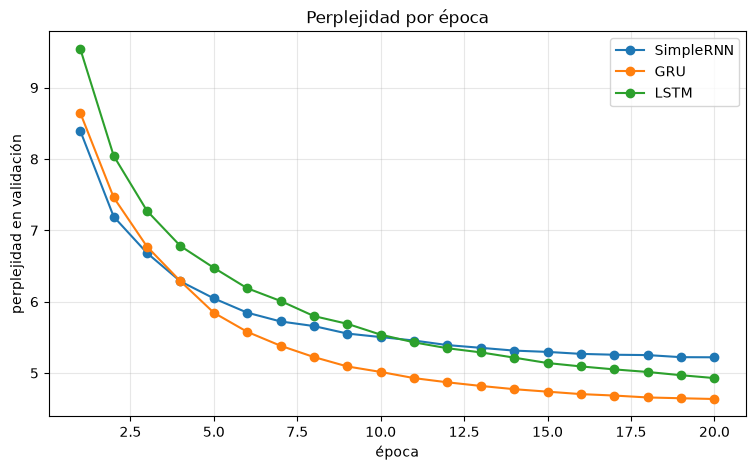

,mejor perplejidad,época del mejor,parámetros,min por época
SimpleRNN,5.221,20.0,90457.0,0.8
GRU,4.636,20.0,239193.0,1.6
LSTM,4.930,20.0,312409.0,1.4


In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
for nombre, r in resultados.items():
    ax.plot(range(1, len(r['ppl']) + 1), r['ppl'], marker='o', label=nombre)
ax.set_xlabel('época')
ax.set_ylabel('perplejidad en validación')
ax.set_title('Perplejidad por época')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame({n: {'mejor perplejidad': round(min(r['ppl']), 3), 'época del mejor': int(np.argmin(r['ppl'])) + 1,
                  'parámetros': r['params'], 'min por época': round(r['min_por_epoca'], 1)}
              for n, r in resultados.items()}).T

Interpretación:
* La GRU tiene la mejor perplejidad (4,64), después la LSTM (4,93) y por último la SimpleRNN (5,22).
* La SimpleRNN baja más rápido al principio porque tiene muchos menos parámetros (90 mil contra 239 mil de la GRU y 312 mil de la LSTM), pero a partir de la época 10 casi no mejora.
* La LSTM arranca peor y recién pasa a la SimpleRNN en la época 11. Al final su curva sigue bajando, con más épocas probablemente se acercaría a la GRU.
* Ningún modelo llegó a cortar por early stopping, la perplejidad seguía bajando en la época 20.
* Los tiempos por época no son muy precisos porque dependen de la carga de la máquina.

Se elige la GRU para probar con dos capas.

### Modelo 4: dos capas recurrentes

Con la mejor celda entre GRU y LSTM se prueba apilar dos capas de 256 unidades.

In [16]:
celda = min(['GRU', 'LSTM'], key=lambda n: min(resultados[n]['ppl']))
print(f'Celda elegida: {celda}')
entrenar(f'{celda}_2capas', crear_modelo(getattr(layers, celda), capas=2))

Celda elegida: GRU
Epoch 1/20


  epoch 1: perplejidad validación = 8.986
339/339 - 167s - 493ms/step - loss: 2.5555


Epoch 2/20


  epoch 2: perplejidad validación = 7.616
339/339 - 186s - 548ms/step - loss: 2.1829


Epoch 3/20


  epoch 3: perplejidad validación = 6.706
339/339 - 180s - 532ms/step - loss: 2.0441


... (31 outputs left out)

  epoch 19: perplejidad validación = 4.531
339/339 - 164s - 482ms/step - loss: 1.5544


Epoch 20/20


  epoch 20: perplejidad validación = 4.505
339/339 - 163s - 480ms/step - loss: 1.5464


GRU_2capas: mejor perplejidad 4.505 en 20 épocas (55.5 min)


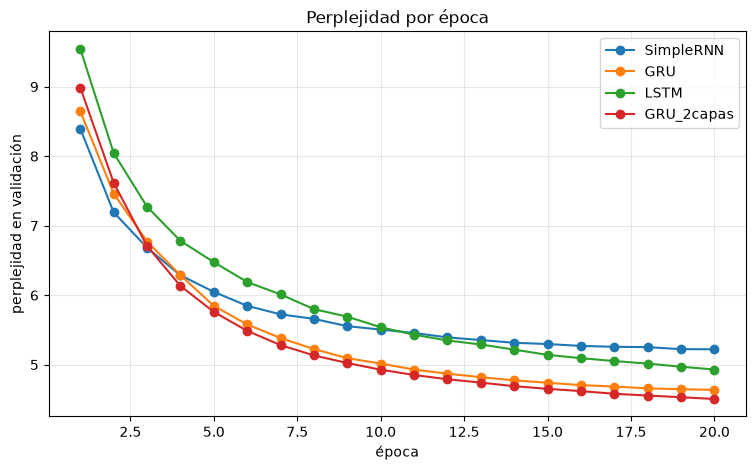

Mejor modelo: GRU_2capas (perplejidad 4.505)


In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
for nombre, r in resultados.items():
    ax.plot(range(1, len(r['ppl']) + 1), r['ppl'], marker='o', label=nombre)
ax.set_xlabel('época')
ax.set_ylabel('perplejidad en validación')
ax.set_title('Perplejidad por época')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

mejor = min(resultados, key=lambda n: min(resultados[n]['ppl']))
print(f'Mejor modelo: {mejor} (perplejidad {min(resultados[mejor]["ppl"]):.3f})')

Interpretación: con dos capas la perplejidad baja de 4,64 a 4,51. Mejora, pero poco, y tiene más del doble de parámetros (unos 634 mil) y tarda casi el doble en entrenar (55 minutos contra 32). Tampoco llegó a cortar por early stopping. Este es el modelo que se usa para generar.

## 6 - Generación de secuencias

Se carga el mejor modelo que guardó el callback. Para generar no hace falta padding porque la red acepta secuencias de cualquier largo, así que se le pasa el texto tal cual (o los últimos 100 caracteres si es más largo).

In [18]:
model = keras.models.load_model(resultados[mejor]['path'])

def encode(text, max_length=max_context_size):
    return np.array([[char2idx[ch] for ch in text.lower()][-max_length:]])

def predict_next(model, batch):
    # model(...) es más rápido que model.predict(...) para lotes chicos
    return model(batch, training=False).numpy()[:, -1, :]

### Greedy search

En cada paso se agrega el carácter más probable.

In [19]:
def generate_seq(model, seed_text, max_length, n_words):
    '''
    Genera `n_words` caracteres a partir de `seed_text` eligiendo siempre el más probable.
    '''
    output_text = seed_text
    for _ in range(n_words):
        y_hat = np.argmax(predict_next(model, encode(output_text, max_length))[0])
        output_text += idx2char[y_hat]
    return output_text

semillas = ['el universo (que otros llaman la biblioteca) ',
            'yo, que tantos hombres he sido, ',
            'en buenos aires ',
            'el laberinto ']

for s in semillas:
    print(repr(generate_seq(model, s, max_length=max_context_size, n_words=200)), '\n')

'el universo (que otros llaman la biblioteca) de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de' 



'yo, que tantos hombres he sido, en la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de' 



'en buenos aires y de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara ' 



'el laberinto de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de la cara de' 



Interpretación: con greedy el modelo entra enseguida en un loop. Con las cuatro frases de entrada termina repitiendo "de la cara de la cara de la cara..." hasta el final. Al elegir siempre el caracter más probable, una vez que aparece esa frase se vuelve a elegir siempre lo mismo. La frase de entrada casi no cambia el resultado.

### Beam search determinístico y estocástico

El beam search mantiene `num_beams` secuencias candidatas y en cada paso se queda con las de mayor probabilidad acumulada:
* Determinístico (`mode='det'`): se queda con las más probables.
* Estocástico (`mode='sto'`): elige al azar según las probabilidades divididas por la temperatura. Con temperatura baja se parece al determinístico y con temperatura alta hay más variedad y más errores.

Las predicciones de todos los beams se hacen juntas en una sola llamada al modelo, y en el modo estocástico se muestrea sin reposición para que no se repitan candidatos.

In [20]:
def select_candidates(pred, num_beams, vocab_size, history_probs, history_tokens, temp, mode):
    # log-probabilidad acumulada de cada continuación posible (beam x carácter)
    pred_large = (np.log(pred + 1e-10) + np.array(history_probs)[:, None]).ravel()

    if mode == 'det':
        idx_select = np.argsort(pred_large)[::-1][:num_beams]
    elif mode == 'sto':
        idx_select = np.random.choice(pred_large.shape[0], num_beams, replace=False, p=softmax(pred_large / temp))
    else:
        raise ValueError(f'Wrong selection mode. {mode} was given. det and sto are supported.')

    new_history_tokens = np.concatenate((np.array(history_tokens)[idx_select // vocab_size],
                                         (idx_select % vocab_size)[:, None]), axis=1)
    return pred_large[idx_select], new_history_tokens


def beam_search(model, num_beams, num_words, input, temp=1, mode='det'):
    encoded = encode(input)
    y_hat = predict_next(model, encoded)
    vocab_size = y_hat.shape[1]

    history_probs, history_tokens = select_candidates(y_hat, num_beams, vocab_size, [0],
                                                      encoded, temp, mode)
    for _ in range(num_words - 1):
        preds = predict_next(model, history_tokens[:, -max_context_size:])
        history_probs, history_tokens = select_candidates(preds, num_beams, vocab_size, history_probs,
                                                          history_tokens, temp, mode)
    # se ordenan los beams de mayor a menor probabilidad acumulada
    orden = np.argsort(history_probs)[::-1]
    return history_tokens[orden], history_probs[orden]

In [21]:
semilla = 'el universo (que otros llaman la biblioteca) '

salidas, probs = beam_search(model, num_beams=10, num_words=200, input=semilla, mode='det')
for s, p in zip(salidas[:3], probs[:3]):
    print(f'log p = {p:.1f}: {decode(s)!r}\n')

log p = -118.9: 'el universo (que otros llaman la biblioteca) de las cosas que los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la palab'

log p = -119.3: 'el universo (que otros llaman la biblioteca) de las cosas que los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la calle'

log p = -119.4: 'el universo (que otros llaman la biblioteca) de las cosas que los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la prime'



In [22]:
for s in semillas[1:]:
    salidas, _ = beam_search(model, num_beams=10, num_words=200, input=s, mode='det')
    print(repr(decode(salidas[0])), '\n')

'yo, que tantos hombres he sido, pero no había sido procedimiento de las palabras de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de la ' 



'en buenos aires y de las palabras de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de la' 



'el laberinto de las palabras de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los hombres de la conciencia de los ' 



Interpretación: el beam search determinístico arma frases mejores que greedy ("de las cosas que los hombres de la conciencia", "pero no había sido procedimiento de las palabras"), pero también termina en un loop, ahora más largo: "de los hombres de la conciencia" se repite con todas las frases de entrada. Los tres mejores beams de la primera frase son casi iguales y solo cambian en la última palabra. Al buscar la secuencia más probable el modelo se queda con frases muy genéricas.

Beam search estocástico con distintas temperaturas, a partir de la misma semilla:

In [23]:
np.random.seed(0)
for temp in [0.2, 0.5, 1.0, 1.5]:
    print(f'===== temperatura {temp}')
    for _ in range(2):
        salidas, _ = beam_search(model, num_beams=10, num_words=200, input=semilla, temp=temp, mode='sto')
        print(repr(decode(salidas[0])), '\n')

===== temperatura 0.2


'el universo (que otros llaman la biblioteca) que el principio de los hombres de la escritura de las palabras de la palabra de las palabras de las palabras de la primera de las palabras de la conciencia de los hombres de la conciencia de la calle' 



'el universo (que otros llaman la biblioteca) de las palabras de la palabra de las palabras de la palabra de las palabras de la conciencia de los hombres de la escritura de los principios de la escritura de las palabras de las palabras que no se ' 

===== temperatura 0.5


'el universo (que otros llaman la biblioteca) que en el principio de los hombres de los hombres de la historia de los principios de la tierra y de las palabras de la escritura de la historia de la tradición de la historia de las ciudades de las c' 



'el universo (que otros llaman la biblioteca) que el infierno de las palabras de la palabra de las palabras de los caballos y de las palabras de las palabras de la conciencia de la noche en el pensamiento de las palabras de las palabras de la con' 

===== temperatura 1.0


'el universo (que otros llaman la biblioteca) el principio de las cosas que las literaturas de la historia de la calle de las cosas del siglo xvi, el mundo es una cara de los principios de la escritura de la primera noche de las calles de la que ' 



'el universo (que otros llaman la biblioteca) de los hombres de la eternidad del cielo, pero no había escritura de las calles y de una tierra y que parecía con el cuerpo que estaban en el principio de la historia de los perros de la espada de la ' 

===== temperatura 1.5


'el universo (que otros llaman la biblioteca) que en ellas de una vida de las palabras y del siglo xvie, todas las cosas que había estado en el tiempo con el pensamiento con la historia de las principas hechos de los destinos de los espectadores ' 



'el universo (que otros llaman la biblioteca) en el diverso del campio de la tierra es una noche de hombres que despreciados por el de la palabra perdición de la cosa que no se propónico de este verdadero y de su propia del libro de la cantada co' 



Interpretación:
* Con temperatura 0.2 es casi igual al determinístico, se repite "las palabras de la palabra de las palabras".
* Con 0.5 aparecen otros temas ("la historia de la tradición", "el infierno", "los caballos"), pero sigue repitiendo.
* Con 1.0 sale el texto más interesante, con frases que suenan a Borges ("la eternidad del cielo", "la historia de los perros de la espada") y sin loops, aunque con errores de concordancia.
* Con 1.5 empieza a inventar palabras ("campio", "propónico", "principas") y se pierde la gramática.

Para este modelo la mejor temperatura parece estar cerca de 1.

## Conclusiones

- Se entrenó un modelo de lenguaje por caracteres con la obra completa de Borges (1,93 millones de caracteres después de limpiar el OCR y 56 caracteres distintos).
- La GRU fue la mejor celda (perplejidad 4,64), después la LSTM (4,93) y la SimpleRNN (5,22). La SimpleRNN aprende rápido al principio pero se estanca antes.
- Con dos capas GRU la perplejidad bajó a 4,51, a cambio del doble de parámetros y de tiempo.
- Ningún modelo cortó por early stopping en 20 épocas, así que entrenando más (con GPU) seguramente mejoraría, sobre todo la LSTM y la GRU de dos capas.
- Greedy y beam search determinístico terminan en loops. El beam search arma mejores frases pero muy genéricas. El estocástico con temperatura cerca de 1 da el texto más variado y parecido al autor; con temperaturas más altas aparecen palabras inventadas.
- La principal limitación es el corpus: los errores del OCR que no se pudieron limpiar también los aprende el modelo. Se podría mejorar usando una versión digital limpia de los textos, entrenando más épocas o con contextos más largos.